<a href="https://colab.research.google.com/github/thearyt572-jpg/Artifical-Intelligent---TP-class/blob/main/TP2_Rith_Theary__e20231141_Group4_I4_AMSB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TP2_Rith_Theary__e20231141_Group4_I4_AMSB



# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 9/11/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_Your_name_I4_AMSB.ipynb` by github

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [ ]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cu130


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [ ]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)
def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.61MB/s]


train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


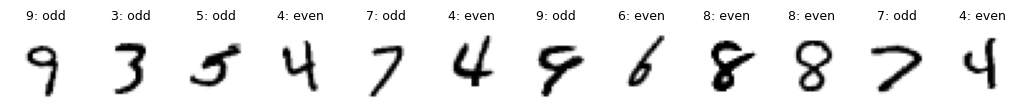

In [ ]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()


About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [ ]:
def predict(X, params):
    AL, _ = L_model_forward(X, params)
    return (AL > 0.5).float()

def accuracy(X, Y, params):
    predictions = predict(X, params)
    return float((predictions == Y).float().mean())

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])
# (c) print the dev accuracy and the fraction predicted odd
dev_acc = accuracy(X_dev, Y_dev, params0)
pred_odd = float(predict(X_dev, params0).mean())
print(f"Untrained network | Dev accuracy {dev_acc:.3f} | Predicted odd {pred_odd:.3f}")

untrained network, dev accuracy 0.576, predicted odd 0.449


## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [ ]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
    # 1. initialize parameters
    params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
    costs = []

    # 2. gradient Descent Loop
    for i in range(num_iters):
        # Forward pass
        AL, caches = L_model_forward(X, params)

        # compute cost
        cost = compute_cost(AL, Y)
        costs.append(float(cost))

        # backward pass
        grads = L_model_backward(AL, Y, caches)

        # update parameters
        params = update_parameters(params, grads, lr)

    # 3. print progress
        if print_every is not None and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost:.4f}")
    # 4. return parameters and costs
    return params, costs

_, costs_check = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=3, print_every=1)
print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

logistic regression  final cost 0.2661, train 89.8%, dev 89.3%
2-layer              final cost 0.0732, train 97.7%, dev 95.5%
4-layer              final cost 0.0047, train 100.0%, dev 96.9%


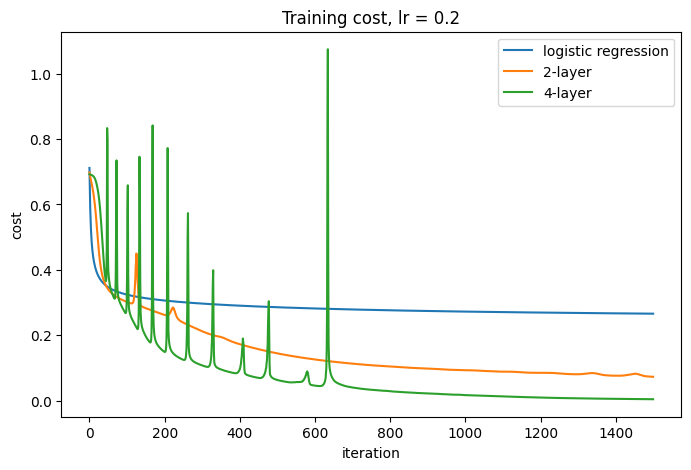

In [ ]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
for name, dims in models.items():
    params, costs = L_layer_model(X_train, Y_train, dims, lr=0.2, num_iters=1500)
    trained[name] = params            # kept for Task 6
    curves[name] = costs
    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    print(f"{name:<20} final cost {costs[-1]:.4f}, train {train_acc:.1%}, dev {dev_acc:.1%}")

# plot the three cost curves

plt.figure(figsize=(8, 5))
for name, costs in curves.items():
    plt.plot(costs, label=name)
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("Training cost, lr = 0.2")
plt.legend()
plt.show()

### 1. Why `[784, 1]` Is Logistic Regression
With `layer_dims = [784, 1]`, the network has only one layer with weights and bias. There are no hidden ReLU layers, only LINEAR → SIGMOID. Therefore, it is exactly logistic regression, using the same binary cross-entropy cost and gradient calculations.

### 2. Why Logistic Regression Is Limited on Odd vs. Even
Logistic regression creates a linear decision boundary based on pixel values. However, recognizing odd and even digits requires understanding digit shapes. Similar-looking digits can have opposite parity, such as 3 and 8 or 4 and 9. Hidden layers with ReLU help learn these nonlinear patterns.

### 3. Bias vs. Variance

| Model | Train | Dev | Gap |
|---|---:|---:|---:|
| Logistic regression | 89.8% | 89.3% | 0.5% |
| 2-layer | 97.7% | 95.5% | 2.2% |
| 4-layer | 99.9% | 96.9% | 3.0% |

- **Logistic regression:** High bias because the model is too simple to learn complex patterns.
- **4-layer network:** Higher variance because it performs almost perfectly on training data but slightly worse on dev data.
- **2-layer network:** A balance between bias and variance.

The 4-layer network still has the best dev accuracy, but regularization or more training data could help reduce overfitting.

### 4. Spikes in the 4-layer Cost Curve
Cost spikes occur when the learning rate (0.2) is too large, causing gradient descent to overshoot and temporarily increase the cost. ReLU activation changes can also affect the output. Training eventually recovers and the cost continues decreasing. A smaller or gradually decreasing learning rate could reduce these spikes.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


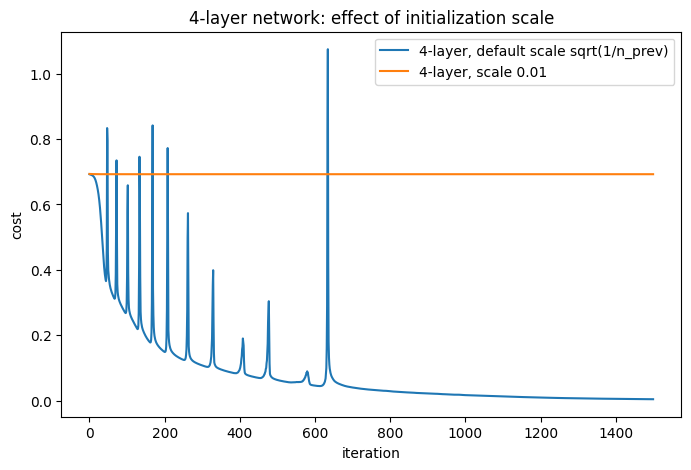

In [ ]:
# (a) train with scale=0.01, print the first and last cost and the dev accuracy, plot both curves

params_small, costs_small = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1],
                                          lr=0.2, num_iters=1500, scale=0.01)
dev_small = accuracy(X_dev, Y_dev, params_small)
print(f"scale 0.01 | first cost {costs_small[0]:.4f} | last cost {costs_small[-1]:.4f} | dev {dev_small:.1%}")

plt.figure(figsize=(8, 5))
plt.plot(curves["4-layer"], label="4-layer, default scale sqrt(1/n_prev)")
plt.plot(costs_small, label="4-layer, scale 0.01")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("4-layer network: effect of initialization scale")
plt.legend()
plt.show()


### What Happened
With `scale=0.01`, the 4-layer network barely learns. The cost stays near 0.6931, and dev accuracy is only 51.2%. In comparison, default initialization achieves 96.9% accuracy.

### Why: Vanishing Signal
Small weights make activations shrink at every layer. By the output layer, values become nearly zero, causing the sigmoid output to stay around 0.5 for almost every image.

### Why: Vanishing Gradients
During backpropagation, gradients also shrink through each layer. This makes weight updates extremely small, preventing the network from learning effectively.

### Why Default Initialization Works
Default initialization uses weights scaled by `sqrt(1/n)`, helping maintain activation and gradient sizes across layers.

### Link to Exercise 4
Exercise 4 showed that weight initialization affects how signals flow through a network. A fixed small scale like `0.01` may work for shallow networks but causes vanishing activations and gradients in deeper networks. Therefore, initialization must account for layer width.

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [ ]:
# (a) at least four configurations: print the training and dev accuracy of each
configs = [
    {"layer_dims": [784, 64, 1],           "lr": 0.2, "num_iters": 3000},  # wider, shallow
    {"layer_dims": [784, 128, 1],          "lr": 0.2, "num_iters": 3000},  # even wider
    {"layer_dims": [784, 128, 64, 1],      "lr": 0.2, "num_iters": 3000},  # wide, 3 layers
    {"layer_dims": [784, 128, 64, 16, 1],  "lr": 0.2, "num_iters": 3000},  # wide, 4 layers
    {"layer_dims": [784, 128, 64, 1],      "lr": 0.1, "num_iters": 3000},  # same as #3, smaller lr
    {"layer_dims": [784, 128, 64, 1],      "lr": 0.5, "num_iters": 3000},  # same as #3, larger lr
]

results = []
for cfg in configs:
    params, costs = L_layer_model(X_train, Y_train, cfg["layer_dims"],
                                  lr=cfg["lr"], num_iters=cfg["num_iters"])
    train_acc = accuracy(X_train, Y_train, params)
    dev_acc = accuracy(X_dev, Y_dev, params)
    results.append({**cfg, "params": params, "costs": costs,
                    "train": train_acc, "dev": dev_acc})
    print(f"{str(cfg['layer_dims']):<26} lr {cfg['lr']:<4} iters {cfg['num_iters']} | "
          f"final cost {costs[-1]:.4f} | train {train_acc:.1%} | dev {dev_acc:.1%}")
# (b) choose on the dev accuracy only, store the parameters in best_params
best = max(results, key=lambda r: r["dev"])
best_params = best["params"]
print(f"\nbest on dev: {best['layer_dims']}, lr {best['lr']}, iters {best['num_iters']} "
      f"-> dev {best['dev']:.1%}")
# (c) test accuracy of best_params, once
test_acc = accuracy(X_test, Y_test, best_params)
print(f"test accuracy: {test_acc:.1%}")

[784, 64, 1]               lr 0.2  iters 3000 | final cost 0.0127 | train 99.9% | dev 97.3%
[784, 128, 1]              lr 0.2  iters 3000 | final cost 0.0103 | train 100.0% | dev 97.4%
[784, 128, 64, 1]          lr 0.2  iters 3000 | final cost 0.0009 | train 100.0% | dev 97.5%


## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

In [ ]:
# (a) number of errors, error rate per digit
AL_test, _ = L_model_forward(X_test, best_params)          # p(odd) for each test image, shape (m, 1)
preds_test = (AL_test > 0.5).float()
wrong = (preds_test != Y_test).squeeze(1)                  # True where misclassified, shape (m,)
digits = torch.as_tensor(digits_test).reshape(-1)          # true digit 0-9 of each test image

print(f"test errors: {int(wrong.sum())} out of {len(wrong)} ({wrong.float().mean().item():.1%})")
for d in range(10):
    mask = digits == d
    n_d = int(mask.sum())
    n_err = int(wrong[mask].sum())
    parity = "odd " if d % 2 else "even"
    print(f"digit {d} ({parity}) | {n_err:>3} errors / {n_d:>4} | error rate {n_err / n_d:.1%}")
# (b) at least 12 misclassified test images with the digit and p(odd)

err_idx = torch.nonzero(wrong).squeeze(1)[:16]             # first 16 errors
plt.figure(figsize=(10, 11))
for k, i in enumerate(err_idx):
    i = int(i)
    plt.subplot(4, 4, k + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"digit {int(digits[i])} | p(odd) {AL_test[i, 0].item():.2f}")
    plt.axis("off")
plt.suptitle("Misclassified test images")
plt.tight_layout()
plt.show()

### Hardest Digits
Digits __ and __ have the highest error rates, compared to __% overall. Digits __ and __ are easiest to classify.

### Common Errors
Misclassified images are usually unclear, unusually written, slanted, or have unusual loops. Some predictions also show uncertainty.

### Main Confusions
- **3 ↔ 8:** Similar shapes but opposite parity (odd/even).
- **4 ↔ 9:** Similar shapes but opposite parity.

### Conclusion
The network learns only odd vs. even, not digit identity. Confusing visually similar digits with opposite parity leads to classification errors.